In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [2]:
# Ubicación del dataset
ruta = Path("../data/resenas_restaurantes.csv")

# Cargar datos
df = pd.read_csv(ruta)

print("Cantidad de registros:", len(df))
print("Columnas:", df.columns.tolist())

df.head()

Cantidad de registros: 730
Columnas: ['negocio', 'texto', 'estrellas', 'estilo', 'sentimiento']


,negocio,texto,estrellas,estilo,sentimiento
0,Restaurante,Mucho minimalismo pero las sillas son insufrib...,2,crítico,negativo
1,Restaurante,"Acústica muy cuidada, se puede hablar sin prob...",5,constructivo,positivo
2,Restaurante,Incluso el servicio de pan y aceites es una ex...,5,neutral,positivo
3,Restaurante,Atmósfera selecta y cuidada. La secuencia de a...,4,formal,positivo
4,Restaurante,"La limpieza, el orden y la estética del local ...",5,neutral,positivo


In [3]:
print("Valores faltantes por columna:")
print(df.isnull().sum())

print("\nReseñas duplicadas:")
print(df["texto"].duplicated().sum())

Valores faltantes por columna:
negocio        0
texto          0
estrellas      0
estilo         0
sentimiento    0
dtype: int64

Reseñas duplicadas:
0


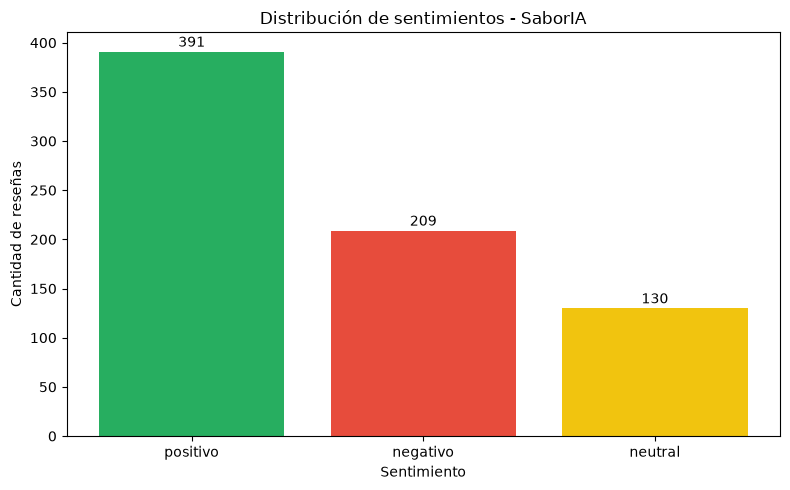

In [4]:
conteo = df["sentimiento"].value_counts()

colores = {
    "positivo": "#27AE60",
    "negativo": "#E74C3C",
    "neutral": "#F1C40F"
}

plt.figure(figsize=(8, 5))

plt.bar(
    conteo.index,
    conteo.values,
    color=[colores[s] for s in conteo.index]
)

plt.title("Distribución de sentimientos - SaborIA")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de reseñas")

for i, valor in enumerate(conteo.values):
    plt.text(i, valor + 5, str(valor), ha="center")

plt.tight_layout()
plt.show()

Estadísticas de longitud:
       longitud_texto  cantidad_palabras
count      730.000000         730.000000
mean        93.832877          15.668493
std         29.736696           5.644203
min         40.000000           5.000000
25%         81.000000          12.000000
50%         88.000000          15.000000
75%        103.000000          18.000000
max        171.000000          33.000000


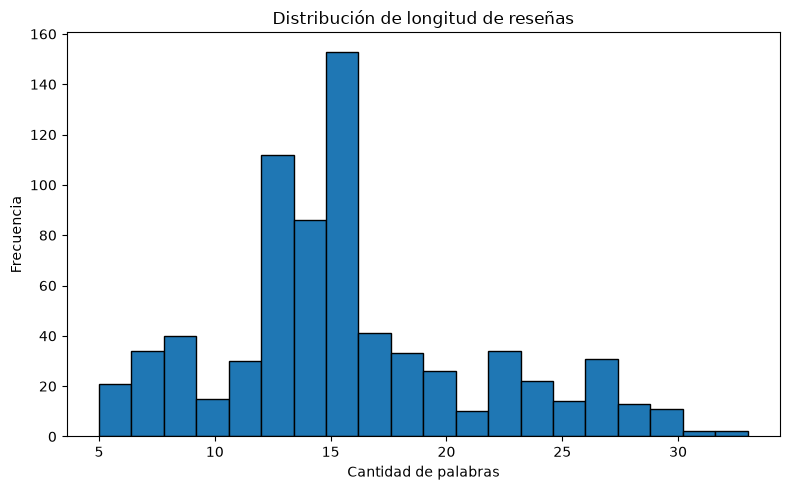

In [5]:
df["longitud_texto"] = df["texto"].astype(str).str.len()
df["cantidad_palabras"] = df["texto"].astype(str).str.split().str.len()

print("Estadísticas de longitud:")
print(df[["longitud_texto", "cantidad_palabras"]].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["cantidad_palabras"], bins=20, edgecolor="black")

plt.title("Distribución de longitud de reseñas")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [6]:
for sentimiento in ["positivo", "negativo", "neutral"]:
    print(f"\n--- {sentimiento.upper()} ---")

    ejemplos = df[df["sentimiento"] == sentimiento]["texto"].head(3)

    for texto in ejemplos:
        print("-", texto)


--- POSITIVO ---
- Acústica muy cuidada, se puede hablar sin problemas. La música ambiente está a un volumen ideal.
- Incluso el servicio de pan y aceites es una experiencia gourmet por derecho propio.
- Atmósfera selecta y cuidada. La secuencia de aperitivos fue el punto álgido del menú.

--- NEGATIVO ---
- Mucho minimalismo pero las sillas son insufribles para una cena de dos horas. La ergonomía no debería sacrificarse por el diseño.
- Nula disposición para adaptar el menú a restricciones dietéticas comunicadas previamente.
- Platos con nombres interminables que luego resultan ser lo de siempre pero mal hecho.

--- NEUTRAL ---
- Está bien para una vez, pero no me entusiasmó.
- Entrantes muy prometedores, pero el plato principal de carne no cumplió las expectativas.
- Ambiente sofisticado, pero el trato del personal de sala fue un tanto distante.


In [7]:
print("Promedio de palabras por reseña:")
print(round(df["cantidad_palabras"].mean(), 2))

Promedio de palabras por reseña:
15.67


## Conclusiones del análisis exploratorio (EDA)

Se realizó un análisis exploratorio de 730 reseñas de restaurantes en español, obtenidas del dataset HorecaReviews-ES.

### 1. Distribución de sentimientos

Se identificaron tres categorías:

- **Positivo:** 391 reseñas (53,6 %).
- **Negativo:** 209 reseñas (28,6 %).
- **Neutral:** 130 reseñas (17,8 %).

Los resultados evidencian un desbalance de clases, con predominio de opiniones positivas. Por este motivo, durante la evaluación de los modelos se utilizarán métricas como precisión, recall y F1-score, además de accuracy.

### 2. Calidad de los datos

Se realizó una revisión de la calidad del dataset utilizando la biblioteca Pandas, con el objetivo de identificar valores faltantes y reseñas duplicadas.

**Valores faltantes encontrados:** 0. No se identificaron valores nulos en ninguna de las columnas del dataset.

**Reseñas duplicadas encontradas:** 0. No se encontraron textos de reseñas repetidos.

Estos resultados indican que el conjunto de 730 reseñas presenta una estructura completa y no contiene duplicados textuales, por lo que no fue necesario realizar una limpieza adicional por estos motivos.
### 3. Longitud de las reseñas

Se analizaron las longitudes de los textos en caracteres y palabras, obteniendo estadísticas descriptivas y una representación gráfica de su distribución.

**Promedio de palabras por reseña:** 15.67.

### 4. Revisión de ejemplos

Se examinaron reseñas positivas, negativas y neutrales para observar diferencias en su contenido y estilo de redacción.

Las etiquetas de sentimiento se derivaron de las calificaciones en estrellas, por lo que pueden existir opiniones ambiguas que requieran una revisión adicional.

### 5. Conclusión general

El dataset permite iniciar experimentos de clasificación supervisada de sentimientos en español mediante técnicas de Procesamiento de Lenguaje Natural.

En las siguientes etapas se aplicarán normalización, tokenización, eliminación selectiva de stop words, stemming, lematización y vectorización TF-IDF.

Posteriormente se entrenarán y compararán los modelos Naive Bayes y regresión logística.

Debe considerarse que las reseñas son sintéticas, por lo que los resultados no necesariamente representan el comportamiento del modelo ante opiniones reales de clientes.